# 03. Selection of Archive Behavior Dimensions

In QD optimization, the behavior map defines the coordinates in which candidate molecules are structured. This makes the choice of the behavior dimensions just as important as the fitness. However, the choice is largely arbitrary, so to narrow the options we set a few conditions:

1. **Continuous gradients**: Dimensions must be **strictly continuous** 

2. **True statistical orthogonality**: Dimensions must be uncorrelated ($|r| < 0.15$). Collinear pairs (e.g., Molecular Weight $\times$ Lipophilicity) confine discoveries to a narrow diagonal, leaving half the archive unpopulated.
3. **No heavy exploitation**: Dimensions must be somewhat resistant to simply adding side chains and changing behavior dramatically. This is important, since our fitness function is a value from a model. We put emphasis on *somewhat*, because as this is an optimization task, exploitation is inevitable.
4. **Interpretability**: Dimensions should have at least some chemical or biological relevance/intepretability
5. **Good!**: In the end, we want the dimensions to actually separate distinct molecules, and reward the search. This can only be validated via testing.

With this in mind, we screen a lot of continuous phisicochemical descriptors, and try one relatively arbitrary choice!

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Descriptors, GraphDescriptors

ROOT = Path.cwd()
while not (ROOT / "chemistry").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Strict publication style
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": False,
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.frameon": True,
    "legend.framealpha": 0.9,
})

def style_axes(ax):
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color("#222222")
    ax.spines["bottom"].set_color("#222222")
    ax.spines["left"].set_linewidth(1.1)
    ax.spines["bottom"].set_linewidth(1.1)


## 1. Screening RDKit Descriptors

We drop categorical and count descriptors. We use all actives, as well as the same quantity of ChemBed-generated molecules.

In [2]:
actives_path = ROOT / "notebooks" / "cache" / "01_chembed" / "reference_actives_minimol.parquet"
if actives_path.exists():
    df_act = pd.read_parquet(actives_path)
    smiles_act = df_act["smiles"].dropna().tolist()
else:
    df_train = pd.read_csv(ROOT / "data" / "predictor" / "predictor_training_data.csv")
    smiles_act = df_train[df_train["target"] == 1]["SMILES"].dropna().tolist()

mols_act = [Chem.MolFromSmiles(s) for s in smiles_act]
mols_act = [m for m in mols_act if m is not None]

cache_dir = ROOT / "notebooks" / "cache" / "03_behavior_map"
cache_dir.mkdir(parents=True, exist_ok=True)
act_cache_p = cache_dir / "continuous_descriptors_actives.parquet"

if act_cache_p.exists():
    df_cont_act = pd.read_parquet(act_cache_p)
else:
    cont_dict = {}
    for name, fn in Descriptors.descList:
        if any(name.startswith(p) for p in ["Num", "RingCount", "fr_", "NOCount", "NHOHCount"]):
            continue
        try:
            vals = np.array([fn(m) for m in mols_act], dtype=float)
            if np.isnan(vals).sum() / len(vals) < 0.05:
                v = vals[~np.isnan(vals)]
                if not np.all(np.equal(np.mod(v, 1), 0)) and len(np.unique(v)) > 50:
                    cont_dict[name] = vals
        except Exception:
            pass
    df_cont_act = pd.DataFrame(cont_dict).dropna()
    df_cont_act.to_parquet(act_cache_p, index=False)

n_total_rdkit = len(Descriptors.descList)
n_continuous = df_cont_act.shape[1]
n_discrete = n_total_rdkit - n_continuous


print(f"Continuous Descriptors Retained: {n_continuous} across {len(df_cont_act):,} active molecules")


Continuous Descriptors Retained: 98 across 2,917 active molecules


## 2. Representative Continuous Descriptor Families

From the 98 strictly continuous descriptors, we select some interpretable continuous descriptors to plot:


findfont: Failed to find font weight medium, now using 400.


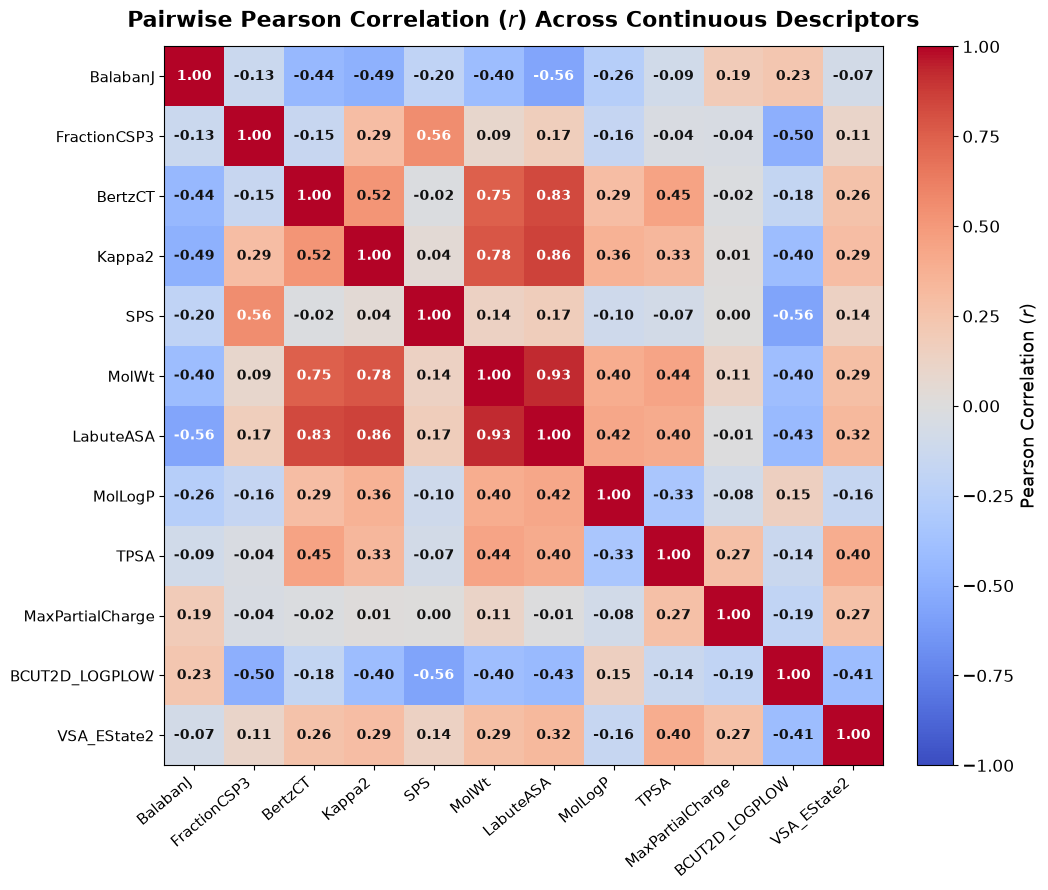

In [3]:
REPRESENTATIVE_DESCRIPTORS = [
    "BalabanJ",
    "FractionCSP3",
    "BertzCT",
    "Kappa2",
    "SPS",
    "MolWt",
    "LabuteASA",
    "MolLogP",
    "TPSA",
    "MaxPartialCharge",
    "BCUT2D_LOGPLOW",
    "VSA_EState2",
]

df_rep = df_cont_act[[c for c in REPRESENTATIVE_DESCRIPTORS if c in df_cont_act.columns]]
corr_rep = df_rep.corr()

fig, ax = plt.subplots(figsize=(10.5, 9))
im = ax.imshow(corr_rep, cmap="coolwarm", vmin=-1.0, vmax=1.0)
ax.set_xticks(np.arange(len(corr_rep.columns)))
ax.set_yticks(np.arange(len(corr_rep.columns)))
ax.set_xticklabels(corr_rep.columns, rotation=40, ha="right", fontsize=11, fontweight="medium")
ax.set_yticklabels(corr_rep.columns, fontsize=11, fontweight="medium")
ax.set_title("Pairwise Pearson Correlation ($r$) Across Continuous Descriptors", pad=14)

for i in range(len(corr_rep)):
    for j in range(len(corr_rep)):
        val = corr_rep.iloc[i, j]
        color = "white" if abs(val) > 0.55 else "#111111"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=10, fontweight="bold")

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Pearson Correlation ($r$)", fontsize=13)
fig.tight_layout()
plt.show()

r_bal_fsp = corr_rep.loc["BalabanJ", "FractionCSP3"]
r_mw_asa = corr_rep.loc["MolWt", "LabuteASA"]
r_mw_logp = corr_rep.loc["MolWt", "MolLogP"]

## 3. Screening of All Continuous Pairs

We chose BalabanJ and Fsp3. We also use appropriate ranges (no active in the training data has a fsp3 above 0.6, so it's not useful to search there). PLenty of other combinations can be tried, but we have to start somewhere.


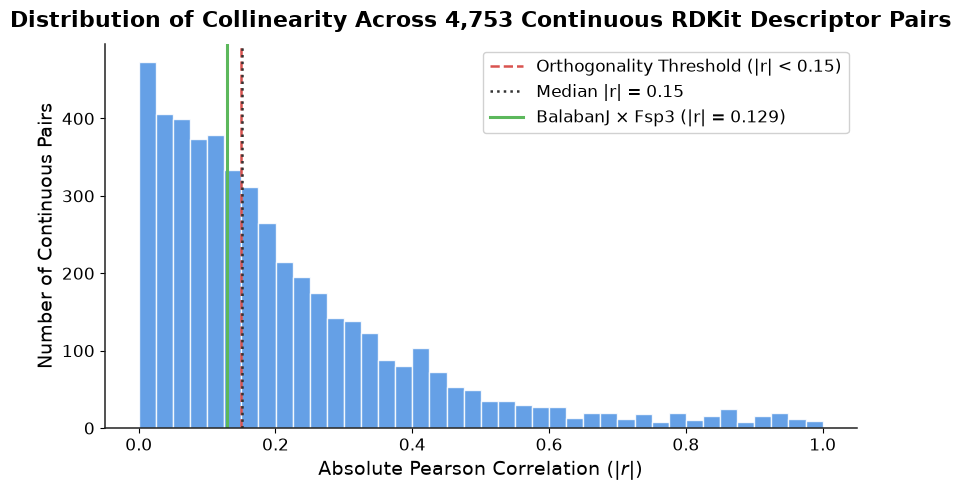

In [4]:
corr_full = df_cont_act.corr().abs()
cols = df_cont_act.columns
all_pairs = []
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        c1, c2 = cols[i], cols[j]
        all_pairs.append({
            "pair": f"{c1} × {c2}",
            "desc1": c1,
            "desc2": c2,
            "abs_r": corr_full.loc[c1, c2]
        })

df_pairs = pd.DataFrame(all_pairs)

fig, ax = plt.subplots(figsize=(8.5, 5))
style_axes(ax)

ax.hist(df_pairs["abs_r"], bins=40, color="#4A90E2", edgecolor="white", alpha=0.85)
ax.axvline(0.15, color="#D9534F", ls="--", lw=1.8, label="Orthogonality Threshold (|r| < 0.15)")
ax.axvline(df_pairs["abs_r"].median(), color="#333333", ls=":", lw=1.8, label=f"Median |r| = {df_pairs['abs_r'].median():.2f}")
ax.axvline(abs(r_bal_fsp), color="#5CB85C", ls="-", lw=2.2, label=f"BalabanJ × Fsp3 (|r| = {abs(r_bal_fsp):.3f})")

ax.set_xlabel("Absolute Pearson Correlation ($|r|$)")
ax.set_ylabel("Number of Continuous Pairs")
ax.set_title("Distribution of Collinearity Across 4,753 Continuous RDKit Descriptor Pairs", pad=12)
ax.legend(loc="upper right", frameon=True)
fig.tight_layout()
plt.show()

pct_orthogonal = (df_pairs["abs_r"] < 0.15).mean() * 100

## 4. 2D Archive Space-Filling

Of course, more than 2 dimensions can be chosen. Here, we just plot some options separate molecules

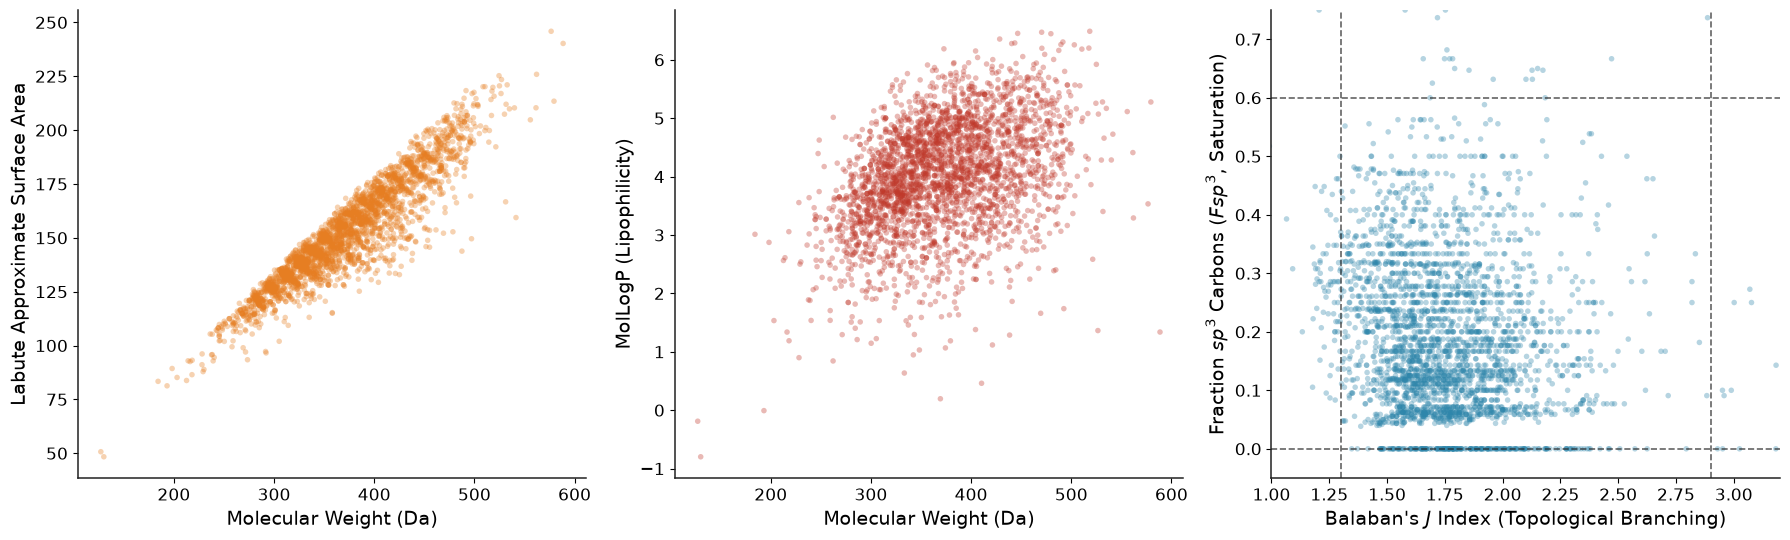

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

ax = axes[0]
style_axes(ax)
ax.scatter(df_cont_act["MolWt"], df_cont_act["LabuteASA"], color="#E67E22", alpha=0.35, s=16, edgecolors="none")
ax.set_xlabel("Molecular Weight (Da)")
ax.set_ylabel("Labute Approximate Surface Area")

ax = axes[1]
style_axes(ax)
ax.scatter(df_cont_act["MolWt"], df_cont_act["MolLogP"], color="#C0392B", alpha=0.35, s=16, edgecolors="none")
ax.set_xlabel("Molecular Weight (Da)")
ax.set_ylabel("MolLogP (Lipophilicity)")

ax = axes[2]
style_axes(ax)
ax.scatter(df_cont_act["BalabanJ"], df_cont_act["FractionCSP3"], color="#2E86AB", alpha=0.35, s=16, edgecolors="none")
ax.axvline(1.3, color="#222222", ls="--", lw=1.2, alpha=0.7)
ax.axvline(2.9, color="#222222", ls="--", lw=1.2, alpha=0.7)
ax.axhline(0.0, color="#222222", ls="--", lw=1.2, alpha=0.7)
ax.axhline(0.6, color="#222222", ls="--", lw=1.2, alpha=0.7)
ax.set_xlabel("Balaban's $J$ Index (Topological Branching)")
ax.set_ylabel("Fraction $sp^3$ Carbons ($Fsp^3$, Saturation)")
ax.set_xlim(1.0, 3.2)
ax.set_ylim(-0.05, 0.75)

fig.tight_layout()
plt.show()
